1.032702569292443e-17
Reading single data file : ../../../data.0000.dbl
5.74763489426533e-05


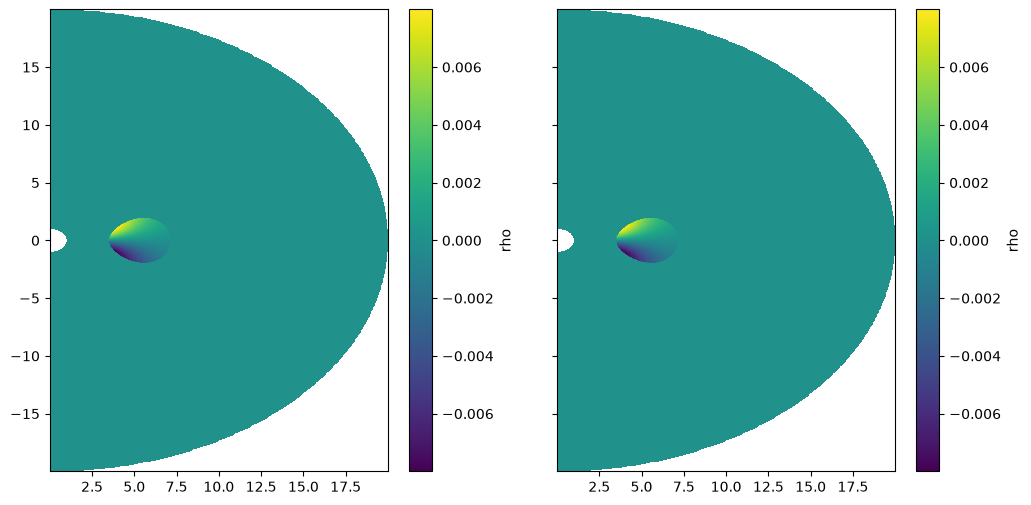

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pyPLUTO.pload import pload
import warnings
warnings.filterwarnings("ignore", category=ResourceWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Importar los centros y la función de cálculo del estado inicial desde grid.py e init.py
from grid import x1_faces, x2_faces, x1_centers, x2_centers
from init import *

rho, prs, vx1, vx2, vx3, A3, tr1 = init(x1_centers, x2_centers)
Bx1s, Bx2s, Bx1, Bx2             = init_B(x1_faces, x2_faces)

print(np.abs(div_B(Bx1s, Bx2s, x1_faces, x2_faces)).max())

vars = np.array([rho, prs, vx1, vx2, vx3, Bx1, Bx2, np.zeros_like(rho), tr1])

x1ft, x2ft     = extend_faces(x1_faces, x2_faces)
vars, Bs1, Bs2 = pad_state(vars, Bx1s, Bx2s)
vars, Bs1, Bs2 = boundary(vars, Bs1, Bs2, x1ft, x2ft)
R, TH = np.meshgrid(x1_centers, x2_centers, indexing='ij')
X = R * np.sin(TH)
Y = R * np.cos(TH)

pluto_data = pload(0, w_dir='../../../')
rho_pluto  = pluto_data.rho # type: ignore

var_test = Bx1

err = np.abs(rho_pluto - rho)

print(np.max(err))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

im1 = ax1.pcolormesh(X, Y, var_test, cmap='viridis', shading='auto')
im2 = ax2.pcolormesh(X, Y, pluto_data.Bx1, cmap='viridis', shading='auto')

plt.colorbar(im1, ax=ax1, label='rho')
plt.colorbar(im2, ax=ax2, label='rho')

# plt.tight_layout()
plt.show()